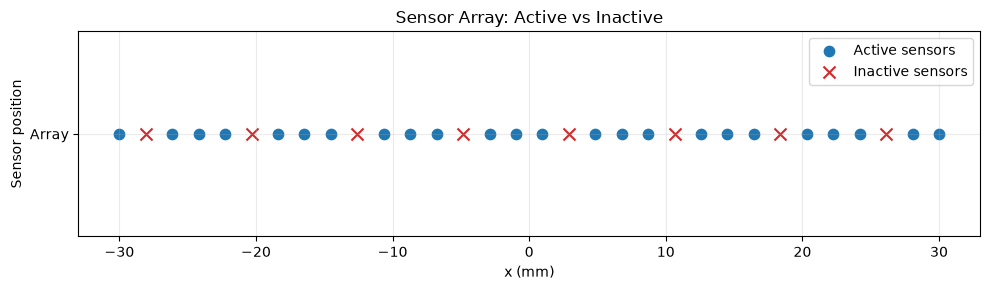

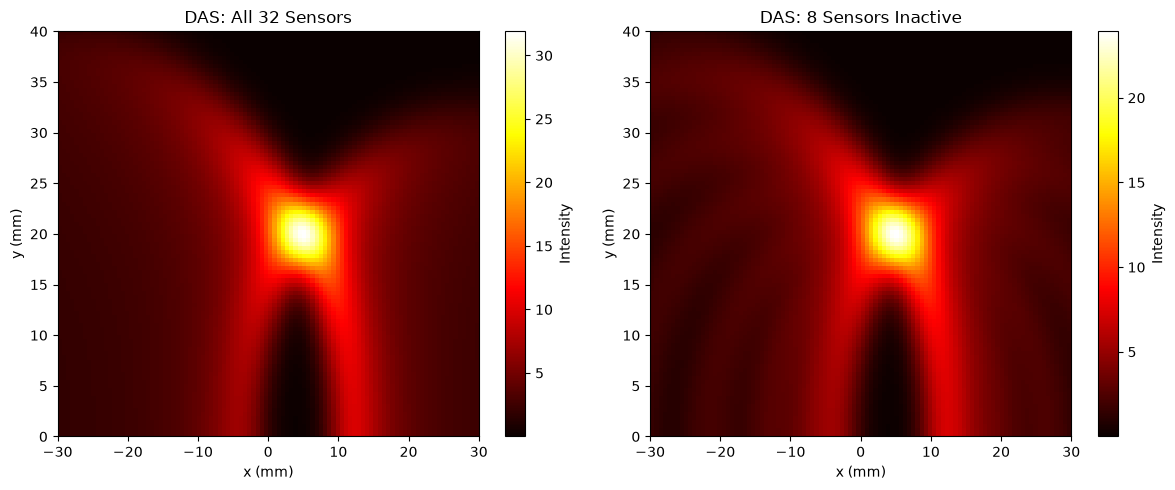

{
    "day": 29,
    "method": "DAS with linear interpolation in time",
    "total_sensors": 32,
    "inactive_sensor_indices_zero_based": [
        1,
        5,
        9,
        13,
        17,
        21,
        25,
        29
    ],
    "inactive_sensor_count": 8,
    "active_sensor_count": 24,
    "inactive_fraction": 0.25,
    "true_source_position_mm": [
        5.0,
        20.0
    ],
    "all_sensors": {
        "peak_intensity": 31.897689381836166,
        "estimated_x_mm": 5.15151515151515,
        "estimated_y_mm": 19.797979797979796,
        "localization_error_mm": 0.2525252525252526
    },
    "inactive_sensors": {
        "peak_intensity": 23.92282763019889,
        "estimated_x_mm": 5.15151515151515,
        "estimated_y_mm": 19.797979797979796,
        "localization_error_mm": 0.2525252525252526
    },
    "raw_image_comparison": {
        "mean_absolute_difference": 1.0958713703784677,
        "rmse": 1.519872799577488,
        "maximum_absolute_difference": 7.97

In [1]:

import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Output directory
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Simulation parameters
c = 1500.0
fs = 10e6
num_sensors = 32

sensor_x = np.linspace(-0.03, 0.03, num_sensors)
sensor_y = np.zeros(num_sensors)

source_x = 0.005
source_y = 0.020

duration = 60e-6
time = np.arange(0, duration, 1 / fs)
dt = time[1] - time[0]

# 2. Generate synthetic sensor signals
distances = np.sqrt(
    (sensor_x - source_x)**2 +
    (sensor_y - source_y)**2
)
arrival_times = distances / c

signals = np.zeros((num_sensors, len(time)))
pulse_width = 1.5e-6

for i in range(num_sensors):
    signals[i] = np.exp(
        -0.5 * ((time - arrival_times[i]) / pulse_width)**2
    )

# 3. Image grid
image_size = 100
x_grid = np.linspace(-0.03, 0.03, image_size)
y_grid = np.linspace(0.0, 0.04, image_size)
X, Y = np.meshgrid(x_grid, y_grid)

# 4. DAS reconstruction function
def reconstruct_das(active_mask):
    image = np.zeros(X.shape, dtype=float)

    for i in range(num_sensors):
        if not active_mask[i]:
            continue

        distance = np.sqrt(
            (X - sensor_x[i])**2 +
            (Y - sensor_y[i])**2
        )
        tof = distance / c

        contribution = np.interp(
            tof.ravel(),
            time,
            signals[i],
            left=0.0,
            right=0.0
        ).reshape(X.shape)

        image += contribution

    return image

# 5. All sensors active
all_active_mask = np.ones(num_sensors, dtype=bool)
image_all = reconstruct_das(all_active_mask)

# 6. Disable 8 evenly distributed sensors
inactive_indices = np.arange(1, num_sensors, 4)
active_mask = all_active_mask.copy()
active_mask[inactive_indices] = False

image_missing = reconstruct_das(active_mask)

# 7. Sensor mask plot
plt.figure(figsize=(10, 3))

plt.scatter(
    sensor_x[active_mask] * 1000,
    sensor_y[active_mask] * 1000,
    color="tab:blue",
    label="Active sensors",
    s=55
)

plt.scatter(
    sensor_x[~active_mask] * 1000,
    sensor_y[~active_mask] * 1000,
    color="tab:red",
    marker="x",
    label="Inactive sensors",
    s=75
)

plt.xlabel("x (mm)")
plt.ylabel("Sensor position")
plt.title("Sensor Array: Active vs Inactive")
plt.yticks([0], ["Array"])
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    output_dir / "day29_sensor_mask.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 8. Compare reconstructions
extent = [
    x_grid[0] * 1000, x_grid[-1] * 1000,
    y_grid[0] * 1000, y_grid[-1] * 1000
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im0 = axes[0].imshow(
    image_all,
    extent=extent,
    origin="lower",
    aspect="auto",
    cmap="hot"
)
axes[0].set_title("DAS: All 32 Sensors")
axes[0].set_xlabel("x (mm)")
axes[0].set_ylabel("y (mm)")
fig.colorbar(im0, ax=axes[0], label="Intensity")

im1 = axes[1].imshow(
    image_missing,
    extent=extent,
    origin="lower",
    aspect="auto",
    cmap="hot"
)
axes[1].set_title("DAS: 8 Sensors Inactive")
axes[1].set_xlabel("x (mm)")
axes[1].set_ylabel("y (mm)")
fig.colorbar(im1, ax=axes[1], label="Intensity")

plt.tight_layout()
plt.savefig(
    output_dir / "day29_inactive_sensor_reconstruction.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 9. Calculate metrics
def peak_metrics(image):
    row, col = np.unravel_index(np.argmax(image), image.shape)

    estimated_x = float(X[row, col])
    estimated_y = float(Y[row, col])

    error_mm = float(
        np.sqrt(
            (estimated_x - source_x)**2 +
            (estimated_y - source_y)**2
        ) * 1000
    )

    return {
        "peak_intensity": float(np.max(image)),
        "estimated_x_mm": estimated_x * 1000,
        "estimated_y_mm": estimated_y * 1000,
        "localization_error_mm": error_mm
    }

difference = image_missing - image_all

results = {
    "day": 29,
    "method": "DAS with linear interpolation in time",
    "total_sensors": int(num_sensors),
    "inactive_sensor_indices_zero_based": inactive_indices.tolist(),
    "inactive_sensor_count": int(np.sum(~active_mask)),
    "active_sensor_count": int(np.sum(active_mask)),
    "inactive_fraction": float(np.mean(~active_mask)),
    "true_source_position_mm": [
        source_x * 1000,
        source_y * 1000
    ],
    "all_sensors": peak_metrics(image_all),
    "inactive_sensors": peak_metrics(image_missing),
    "raw_image_comparison": {
        "mean_absolute_difference": float(np.mean(np.abs(difference))),
        "rmse": float(np.sqrt(np.mean(difference**2))),
        "maximum_absolute_difference": float(np.max(np.abs(difference)))
    },
    "note": (
        "Synthetic Gaussian-pulse simulation. "
        "No missing-data interpolation across sensors was applied. "
        "Image amplitudes are not normalized separately."
    )
}

with open(
    output_dir / "day29_inactive_sensor_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, indent=4)

print(json.dumps(results, indent=4))
print("\nDay 29 completed!")
print(f"Outputs saved to: {output_dir}")
